# Fixed multiproduct Hamiltonian simulation

This original notebook accompanies coherent two-term LCU/OAA and classical weighted observables. It reads finite producer records and exposes the primitive generator. The first cell displays producer status; saved execution counts and outputs record notebook execution.

The Hamiltonian is the open ZZ/X chain. All reference matrices are bounded at three system spins; large source construction is separate.


In [1]:
from pathlib import Path
import json, os, sys
from IPython.display import display, Markdown, SVG
root = Path.cwd()
if not (root / "src/openquantum/simulation/multiproduct.py").is_file():
    root = root.parent
sys.path.insert(0, str(root / "src"))
from openquantum.simulation import multiproduct as mpf
records = Path(os.environ.get("OPENQUANTUM_MULTIPRODUCT_RECORDS", str(root / "assets/generated/simulation/multiproduct")))
study = json.loads((records / "study.json").read_text())
print({"status": study["status"], "cases": len(study["cases"]), "producer": study["source"]["source_commit"]})


{'status': 'generated_and_small_checked', 'cases': 14, 'producer': None}


## Primitive small circuit

The five-wire figure is a complete unamplified two-spin/r1 trial: initial resets, coefficient preparation, both controlled Strang branches, uncomputation and every readout. Padding and controls are actual gates; the figure does not treat access as a free oracle.


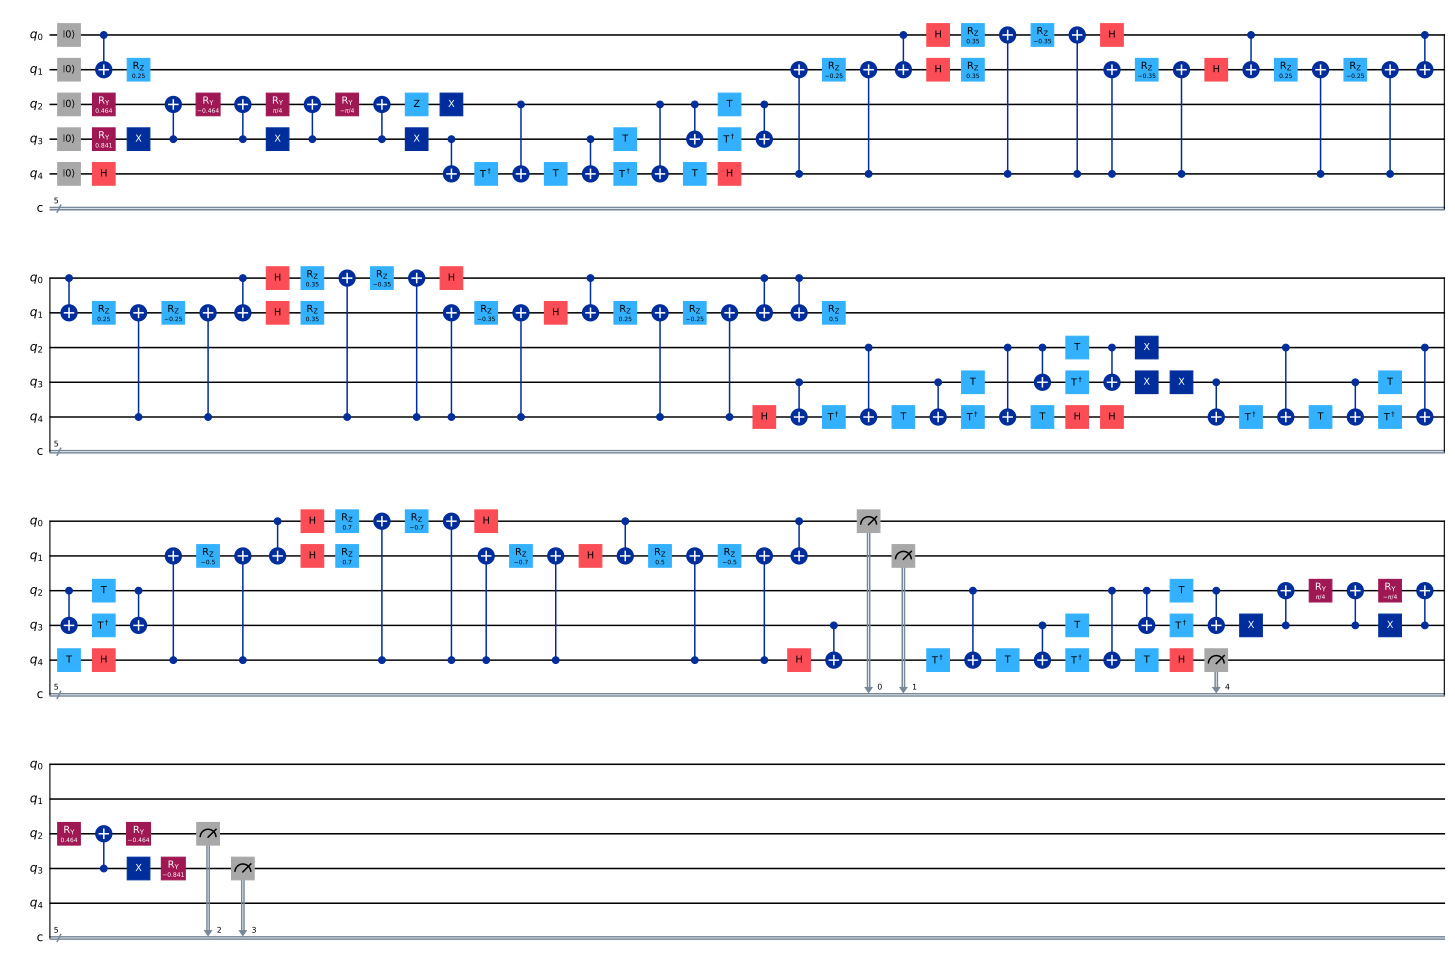

In [2]:
display(SVG((records / "small-lcu-circuit.svg").read_text()))


## Independent finite comparisons

Operator errors, acceptance and observable biases have separate meanings. The classical combination supplies a weighted expectation, while accepted LCU/OAA supplies a conditional state. Discarding OAA ancillas supplies an unconditional reduced channel.


In [3]:
header = "|n|r|A operator error|F operator error|p LCU min|p OAA min|classical Z bias|\n|---:|---:|---:|---:|---:|---:|---:|"
rows = []
for case in study["cases"]:
    value = case["validation"]
    if value.get("performed") and case["n_system"] in (2, 3):
        rows.append(f"|{case['n_system']}|{case['steps']}|{value['A_operator_error']:.3g}|{value['F_operator_error']:.3g}|{value['lcu_min_acceptance_numeric']:.6f}|{value['oaa_min_acceptance_numeric']:.6f}|{value['classical_weighted_Z_error']:.3g}|")
display(Markdown(header + "\n" + "\n".join(rows)))


|n|r|A operator error|F operator error|p LCU min|p OAA min|classical Z bias|
|---:|---:|---:|---:|---:|---:|---:|
|2|1|0.0416|0.0173|0.250000|0.995684|0.0213|
|2|2|0.00234|0.00164|0.250000|0.999992|0.00138|
|2|4|0.000141|0.000106|0.250000|1.000000|8.37e-05|
|2|8|8.71e-06|6.63e-06|0.250000|1.000000|5.18e-06|
|3|1|0.119|0.0838|0.250000|0.982293|0.0201|
|3|2|0.00492|0.00405|0.250000|0.999981|0.000709|
|3|4|0.000275|0.000228|0.250000|1.000000|4.11e-05|
|3|8|1.67e-05|1.39e-05|0.250000|1.000000|2.54e-06|
|2|32|3.39e-08|2.59e-08|0.250000|1.000000|2.02e-08|
|3|32|6.47e-08|5.37e-08|0.250000|1.000000|9.88e-09|

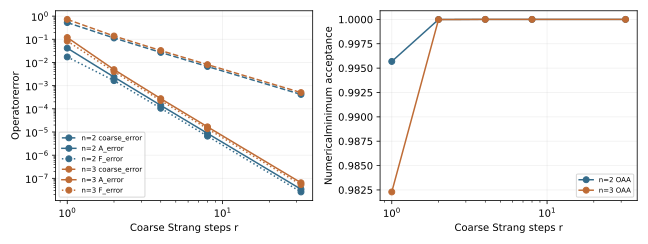

In [4]:
display(SVG((records / "convergence.svg").read_text()))


## Reusable code and separate scale limits

The returned circuits contain primitive gates and retain the OAA global minus sign. Circuit generation does not compute a Hamiltonian or state matrix. Counts alone are not an executed large-system simulation or a physical estimate.


In [5]:
small = mpf.build_evolution(n=1, time=.5, steps=1, method="oaa")
print({"qubits": small.num_qubits, "primitive_counts": dict(small.count_ops()), "global_phase": float(small.global_phase)})
print(mpf.scalar_counts(n=32, steps=1, method="oaa-channel"))


{'qubits': 4, 'primitive_counts': {'cx': 116, 'h': 46, 't': 44, 'tdg': 40, 'x': 38, 'ry': 30, 'rz': 18, 'z': 3}, 'global_phase': 3.141592653589793}
{'method': 'oaa-channel', 'system_qubits': 32, 'logical_qubits': 35, 'selector_qubits': 2, 'clean_work_qubits': 1, 'steps': 1, 'time': 1.0, 'J': 1.0, 'h': 0.7, 'unitary_gate_counts': {'h': 604, 'x': 38, 'z': 3, 't': 44, 'tdg': 40, 'cx': 2906, 'ry': 30, 'rz': 1692}, 'unitary_operations': 5357, 'branch_steps_per_B': 3, 'B_calls': 3, 'scalar_only': True, 'physical_resource_estimate': None}


## Complete logical resource proposal

All coefficient preparation, both SELECT branches, work, uncomputation, reflections, input initialization, retries/discards and measurements are counted. Sampling populations and synthesis/physical allowances are proposals; no physical, synthesis or hardware execution is claimed. The supplied finite commutator certificate is conservative second order even where the fixed-size curve shows fourth-order cancellation.


In [6]:
selected = next((case for case in study["cases"] if case["n_system"] == 2 and case["steps"] == 32), study["cases"][0])
summary = {}
for method, value in selected["methods"].items():
    proposal = value["resource_proposal"]
    summary[method] = {"complete_preparations_capped": proposal["complete_preparations_capped"], "ideal_bound_supported": proposal["ideal_algorithm_allowance_supported"], "physical_runtime": proposal["physical_runtime"], "total_accuracy_verified": proposal["total_accuracy_verified"]}
print(summary)


{'lcu': {'complete_preparations_capped': 812000, 'ideal_bound_supported': True, 'physical_runtime': None, 'total_accuracy_verified': False}, 'oaa': {'complete_preparations_capped': 42000, 'ideal_bound_supported': True, 'physical_runtime': None, 'total_accuracy_verified': False}, 'oaa-channel': {'complete_preparations_capped': 14000, 'ideal_bound_supported': True, 'physical_runtime': None, 'total_accuracy_verified': False}, 'fine': {'complete_preparations_capped': 31112, 'ideal_bound_supported': True, 'physical_runtime': None, 'total_accuracy_verified': False}, 'coarse': {'complete_preparations_capped': 7778, 'ideal_bound_supported': True, 'physical_runtime': None, 'total_accuracy_verified': False}}


## Retained acceptance counterexample

For the separate source fixture fine=I and coarse=−I, one OAA round decreases acceptance from 25/36 to 25/729. Normalized conditional states remain exact, so this is not a generic state-accuracy failure. It is outside the common-H Strang simulation family.


In [7]:
print(study["negative_fixture"])


{'lcu': {'block_reference_error': 1.2212453270876722e-15, 'clean_work_leakage': 5.551115123125784e-17, 'acceptance': 0.6944444444444424, 'ideal_acceptance': '25/36', 'normalized_state_error': 0.0, 'raw_operator_error_to_identity': 0.6666666666666667, 'scope': 'explicitphase fixture Uf=I,Uc=-I outside common-H Strang family; not a conditional-state failure'}, 'oaa': {'block_reference_error': 8.604287459712422e-16, 'clean_work_leakage': 9.980844584221445e-17, 'acceptance': 0.034293552812071006, 'ideal_acceptance': '25/729', 'normalized_state_error': 1.7209208811930075e-17, 'raw_operator_error_to_identity': 0.8148148148148149, 'scope': 'explicitphase fixture Uf=I,Uc=-I outside common-H Strang family; not a conditional-state failure'}}


## References and limitations

Original code uses pinned Qiskit 2.6.2 (Apache-2.0), NumPy and SciPy. References: Low et al. arXiv:1907.11679v2; Carrera Vazquez et al., Quantum 7,1067, DOI10.22331/q-2023-07-25-1067; Mizuta, Quantum 10,1974, DOI10.22331/q-2026-01-19-1974. The optimized high-order multiproduct family, physical costs and mechanized proofs remain planned.
